In [15]:
import numpy as np
import onnxruntime as ort
from PIL import Image

In [16]:
# 1. Load the exported ONNX model
onnx_model_path = r'D:\MTEC\Image-Processing\Cat and Dog Classification\cat_dog_classifier.onnx'
session = ort.InferenceSession(onnx_model_path)

# Get input details from the model
input_name = session.get_inputs()[0].name
print(f"Model Input Name: {input_name}")

Model Input Name: image_input:0


In [17]:
# 2. Load and preprocess the test image
# Cropped cat image
# image_path = r'D:\MTEC\Image-Processing\Test pic\c614d78f-5ce9-4ff7-b8ed-2d3cb6208659.jfif'  # Replace with your image path
# Original cat image
# image_path = r'D:\MTEC\Image-Processing\Test pic\S__80502792_0.jpg'

image_path = r'D:\MTEC\Image-Processing\Test pic\2a97814fb6a99e84e885c5e232c5e3e0.jpg'

In [18]:
with Image.open(image_path) as img:
    img = img.convert('RGB')
    img_array = np.array(img, dtype=np.float32)

In [19]:
# 3. Add batch dimension to match model input shape (Batch, Height, Width, Channels)
input_data = np.expand_dims(img_array, axis=0)

# 4. Run inference using ONNX Runtime
outputs = session.run(None, {input_name: input_data})
score = outputs[0][0][0]  # Sigmoid output score (0 to 1)

# 3. Add batch dimension to match model input shape (Batch, Height, Width, Channels)
input_data = np.expand_dims(img_array, axis=0)

# 4. Run inference using ONNX Runtime
outputs = session.run(None, {input_name: input_data})
probabilities = outputs[0][0]  # Array of 3 probabilities: [Cat, Dog, Other]

# 5. Interpret the prediction results
class_names = ['Cat', 'Dog', 'Other']
pred_class_idx = np.argmax(probabilities)
pred_class = class_names[pred_class_idx]
confidence = probabilities[pred_class_idx] * 100

print(f"Prediction: {pred_class} (Confidence: {confidence:.2f}%)")

Prediction: Dog (Confidence: 94.97%)


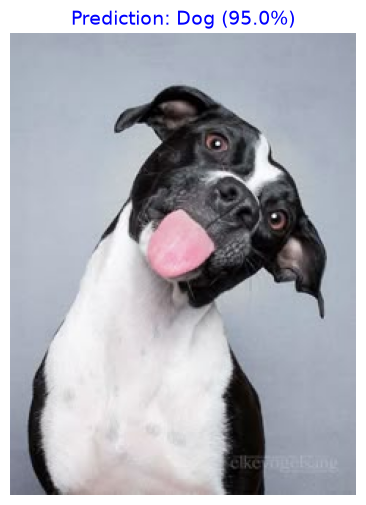

In [20]:
import matplotlib.pyplot as plt

# 6. Visualise the image along with the prediction result
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis('off')
plt.title(f"Prediction: {pred_class} ({confidence:.1f}%)", fontsize=14, color='blue')
plt.show()

In [21]:
# import matplotlib.pyplot as plt
# import numpy as np
# import tensorflow as tf
# from tensorflow.keras import layers, Sequential

# original_image = tf.keras.utils.load_img(image_path)
# original_array = tf.keras.utils.img_to_array(original_image)
# original_shape = original_array.shape

# print(f"Original: {original_shape}")

# preprocessing_model = Sequential(
#     [
#         layers.Resizing(160, 160, input_shape=(None, None, 3)),
#     ]
# )

# input_tensor = np.expand_dims(original_array, axis=0)

# resized_tensor = preprocessing_model(input_tensor)

# resized_array = resized_tensor[0].numpy().astype(np.uint8)

# print(f"Size after Resizing: {resized_array.shape}")

# plt.figure(figsize=(10, 5))

# plt.subplot(1, 2, 1)
# plt.imshow(original_array.astype(np.uint8))
# plt.title(f"Original Image\nSize: {original_shape[1]}x{original_shape[0]}")
# plt.axis("off")
# plt.subplot(1, 2, 2)
# plt.imshow(resized_array)
# plt.title(f"Resized by Layer (160x160)\nSize: {resized_array.shape[1]}x{resized_array.shape[0]}")
# plt.axis("off")
# plt.tight_layout()
# plt.show()